In [125]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, average_precision_score

import seaborn as sns
 

## EDA

In [126]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [127]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [133]:
alive_as_number = df["alive"].map({"no": 0, "yes": 1})
matches = df["survived"].eq(alive_as_number)
mismatches = df.loc[~matches, ["survived", "alive"]]

print(f"Matching rows: {matches.sum()} / {len(df)}")
print(f"Mismatched rows: {len(mismatches)}")
if not mismatches.empty:
    display(mismatches)

assert matches.all(), "df.survived and df.alive do not match after mapping yes/no to 1/0."

Matching rows: 891 / 891
Mismatched rows: 0


### Data cleaning

In [134]:
data = df.copy()
y = data["survived"]

### Feature engineering

In [135]:
data["family_size"] = data["sibsp"] + data["parch"] + 1
data["is_alone"] = (data["family_size"] == 1).astype(int)

X = data.drop(
    columns=["survived", "alive", "class", "who", "adult_male", "alone"],
    errors="ignore"
)

In [136]:
numeric_features = ["age", "sibsp", "parch", "fare", "family_size", "is_alone"]
categorical_features = ["pclass", "sex", "embarked"]

preprocessor = ColumnTransformer([
    ("numeric", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), numeric_features),
    ("categorical", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), categorical_features),
])

### Model training

In [137]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(preprocessor, LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

ValueError: Some column names are not columns of the dataframe: {'is_alone', 'family_size'}

Precision for survivors: 0.8103448275862069
Recall for survivors: 0.6811594202898551


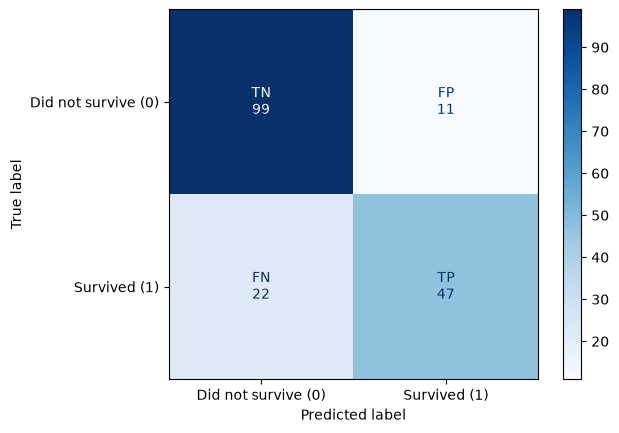

In [ ]:
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did not survive (0)", "Survived (1)"]
)
disp.plot(cmap="Blues", values_format="d")

for text, label, count in zip(
    disp.ax_.texts,
    ["TN", "FP", "FN", "TP"],
    cm.ravel()
):
    text.set_text(f"{label}\n{count}")
print("Precision for survivors:", precision_score(y_test, y_pred, pos_label=1))
print("Recall for survivors:", recall_score(y_test, y_pred, pos_label=1))
plt.show()

**Classification Metrics**
$$
\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}}
$$
$$
\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}
$$
$$
\text{Accuracy} = \frac{\text{True Positives} + \text{True Negatives}}{\text{Total Observations}}
$$

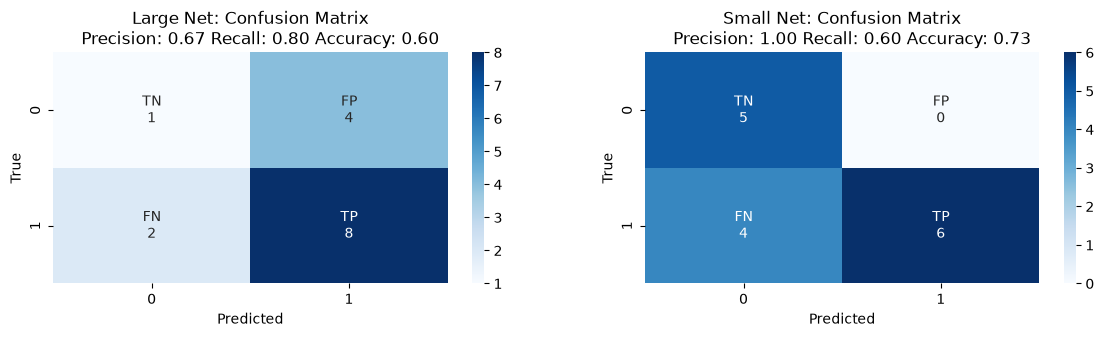

In [ ]:
def plot_confusion_matrix(y_true, y_pred, ax, label):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    annotations = np.array([[f'TN\n{cm[0, 0]}', f'FP\n{cm[0, 1]}'],
                            [f'FN\n{cm[1, 0]}', f'TP\n{cm[1, 1]}']])
    sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues', ax=ax)
    precision_large, recall_large, accuracy_large = precision_score(y_true, y_pred), recall_score(y_true, y_pred), accuracy_score(y_true, y_pred)
    ax.set_title(f"""{label} Net: Confusion Matrix
    Precision: {precision_large:.2f} Recall: {recall_large:.2f} Accuracy: {accuracy_large:.2f}""")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
 
y_true =  np.array([1, 1, 1, 1, 1, 1 ,1 ,1 ,1 ,1, 0, 0, 0, 0, 0])
y_pred1 = np.array([1, 1, 1, 1, 1, 1 ,1 ,1 ,0, 0, 1, 1, 1, 1, 0]) # Large
y_pred2 = np.array([1, 1, 1, 1, 1, 1 ,0 ,0 ,0, 0, 0, 0, 0, 0, 0]) # Small
 
fig, ax = plt.subplots(1, 2, figsize=(14, 3))
plot_confusion_matrix(y_true, y_pred1, ax[0], "Large")
plot_confusion_matrix(y_true, y_pred2, ax[1], "Small")
plt.show()
 
 